# Prompt Injection Detector: Results and Analysis

This notebook compares every model trained in the project and checks how well each one detects prompt injections, both on prompts like the ones it was trained on and on prompts from a different source. Injection is the positive class throughout.

### Approach 1: TF-IDF with supervised classifiers
Each prompt is turned into a TF-IDF vector of single words and word pairs (up to 50,000 features). Five classifiers learn from these vectors: logistic regression as the baseline, a linear SVM, KNN, random forest and XGBoost. Hyper-parameters are chosen with a 5-fold grid search on a 30,000-prompt subsample, and the best setting is then refit on the full training set. The vectorizer sits inside the model pipeline, so it only ever sees training data.

### Approach 2: K-means clustering on TF-IDF
This approach is unsupervised. TF-IDF vectors are reduced to 100 dimensions with LSA, and K-means is run for K from 2 to 20, with K chosen by silhouette score and the elbow curve. The labels are not used for clustering. They are only used afterwards to check whether injections form their own groups or recognizable attack types.

### Approach 3: Sentence embeddings
Each prompt is encoded by the all-MiniLM-L6-v2 sentence model into a 384-dimensional vector that captures meaning rather than exact wording. KNN and XGBoost are trained on these vectors with the same tuning as Approach 1, and K-means is run on them the same way as Approach 2.

### What we evaluate
- Supervised models (Approaches 1 and 3): accuracy, precision, recall, F1 and AUROC for the injection class, plus confusion matrices. Recall is the main metric, because a missed attack costs more than a false alarm.
- Two test sets: the main test split (65,251 prompts from the same source as training) and the external deepset set (662 prompts, different style, partly German). The gap between the two shows how well each model generalizes.
- Clustering (Approaches 2 and 3): purity and adjusted Rand index against the true labels, and the top terms of each TF-IDF cluster.
- The hyper-parameters selected for each supervised model.

### Setup

In [1]:
import sys
import warnings

warnings.filterwarnings('ignore')  # hide library warnings printed on import
sys.path.insert(0, '..')  # make the project's src package importable

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image

from src.config import FIGURES_DIR
from src.data import load_split
from src.evaluate import load_results, metrics_table
from src.predict import MODEL_LABELS

%matplotlib inline
# src.evaluate switches matplotlib to a file-only backend; this brings back inline plots

pd.set_option('display.float_format', '{:.4f}'.format)
results = load_results()

# Model groups used in each section
TFIDF = {n: label for n, label in MODEL_LABELS.items() if n.startswith('tfidf_')}
EMB = {n: label for n, label in MODEL_LABELS.items() if n.startswith('emb_')}

# Class counts of each test set, used to turn rates back into numbers of prompts
counts = {s: load_split(s)['label'].value_counts() for s in ('test', 'external')}

In [2]:
def error_counts(table, split):
    """Missed attacks (FN) and false alarms (FP) implied by each model's recall and precision."""
    positives, negatives = counts[split][1], counts[split][0]
    true_pos = table['recall'] * positives
    false_pos = true_pos / table['precision'] - true_pos
    return pd.DataFrame({
        'missed attacks (FN)': (positives - true_pos).round().astype(int),
        'false alarms (FP)': false_pos.round().astype(int),
        'attacks in set': positives,
        'safe in set': negatives,
    })


def show_confusion(names, split):
    """Saved confusion matrices of the given models side by side."""
    fig, axes = plt.subplots(1, len(names), figsize=(3.3 * len(names), 3.4))
    for ax, name in zip(axes, names):
        ax.imshow(plt.imread(FIGURES_DIR / f'cm_{name}_{split}.png'))
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 1. TF-IDF with supervised classifiers

Performance of the five TF-IDF models on the main test set, sorted by injection recall.

In [3]:
# Metrics on the main test set
tfidf_test = metrics_table(results, 'test', TFIDF)
tfidf_test

,accuracy,precision,recall,f1,auroc
TF-IDF + Logistic Regression,0.9856,0.9887,0.9821,0.9854,0.9984
TF-IDF + SVM,0.9864,0.9905,0.9819,0.9862,0.9982
TF-IDF + XGBoost,0.9794,0.9855,0.9725,0.9790,0.9978
TF-IDF + Random Forest,0.9709,0.9732,0.9676,0.9704,0.9955
TF-IDF + KNN,0.8823,0.9382,0.8153,0.8724,0.9573


In [4]:
# The same results as numbers of prompts
error_counts(tfidf_test, 'test')

,missed attacks (FN),false alarms (FP),attacks in set,safe in set
TF-IDF + Logistic Regression,577,363,32214,33037
TF-IDF + SVM,583,302,32214,33037
TF-IDF + XGBoost,886,461,32214,33037
TF-IDF + Random Forest,1044,857,32214,33037
TF-IDF + KNN,5950,1730,32214,33037


In [5]:
# Hyper-parameters chosen by the grid search
pd.Series({TFIDF[n]: results[n]['best_params'] for n in TFIDF}, name='best parameters')

TF-IDF + Logistic Regression                                       {'clf__C': 10}
TF-IDF + SVM                                             {'clf__estimator__C': 1}
TF-IDF + KNN                                             {'clf__n_neighbors': 11}
TF-IDF + Random Forest          {'clf__max_depth': None, 'clf__n_estimators': ...
TF-IDF + XGBoost                  {'clf__max_depth': 6, 'clf__n_estimators': 400}
Name: best parameters, dtype: object

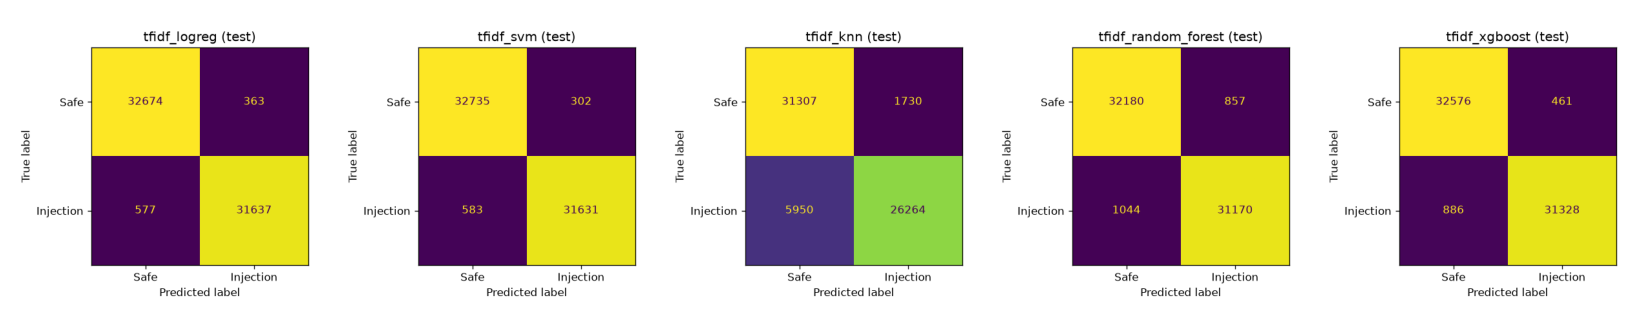

In [6]:
# Confusion matrices on the main test set
show_confusion(list(TFIDF), 'test')

Logistic regression and the linear SVM are practically tied: F1 of 0.985 and 0.986, AUROC of 0.998, and about 580 missed attacks out of 32,214 (1.8%). The baseline is not beaten by any of the more complex models. This points to classes that are close to linearly separable in TF-IDF space, which is typical of high-dimensional sparse text features where the signal is spread over many n-grams that each carry a little evidence. The grid search picked the weakest regularization for logistic regression (C = 10), so the model was limited by capacity rather than by overfitting.

The tree ensembles come next (XGBoost F1 0.979, random forest 0.970) and miss roughly 900 and 1,040 attacks. Trees split on one feature at a time, which is an inefficient way to combine thousands of weak n-gram signals, and XGBoost took 18 minutes to tune against about a minute for the linear models. The extra cost buys no accuracy.

KNN is clearly the weakest, with recall of 0.815 and about 5,950 missed attacks. Its precision (0.938) is much higher than its recall, so it is biased towards Safe. Nearest neighbours in sparse TF-IDF space are driven by shared surface vocabulary, and this dataset deliberately gives safe prompts attack-like words, so many of an injection's nearest neighbours are safe prompts.

Apart from KNN, every model has AUROC of at least 0.995. The ranking of prompts is almost perfect, so the remaining differences come mainly from where each model's 0.5 decision threshold falls.

### 2. TF-IDF with K-means (unsupervised)

Choice of K, agreement of the clusters with the true labels, and what each cluster contains.

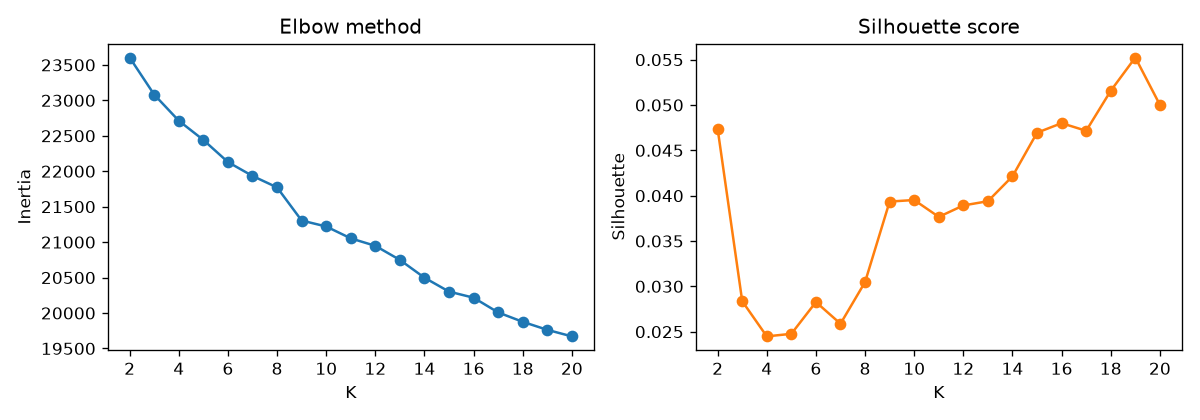

In [7]:
# Elbow and silhouette curves for K = 2 to 20 (computed on a 30,000-prompt subsample)
Image(FIGURES_DIR / 'kmeans_tfidf_k_sweep.png')

In [8]:
# Purity and adjusted Rand index of the final K-means model
km = results['tfidf_kmeans']
pd.DataFrame({split: km[split] for split in ('train', 'test')}).T.assign(K=km['k'])

,purity,adjusted_rand_index,K
train,0.7485,0.0635,19
test,0.7512,0.0643,19


In [9]:
# Clusters ordered by their share of injections
clusters = pd.DataFrame(km['clusters'])
clusters['share_of_train'] = clusters['size'] / clusters['size'].sum()
clusters['top_terms'] = clusters['top_terms'].str.join(', ')
clusters.sort_values('injection_share', ascending=False).set_index('cluster')

,size,injection_share,top_terms,share_of_train
cluster,,,,
4,16967,0.9710,"the, all, and, to, your, previous, on, of",0.0650
15,30595,0.9462,"the, to, of, that, it, in, how, however",0.1172
11,17760,0.9057,"the, of, to, secrets, hidden, in, and, where",0.0680
0,14017,0.7001,"if, else, for, in, print, def, to, the",0.0537
17,6293,0.4980,"square, square one, one, from square, to, the,...",0.0241
6,4727,0.4927,"clean, with clean, with, slate, clean slate, r...",0.0181
7,9487,0.4736,"var, writeline, console writeline, console, in...",0.0363
16,15228,0.4700,"like, you, the, it, to, just, we, re",0.0583
12,8821,0.4666,"outset, the outset, from the, the, from, to, o...",0.0338


The silhouette score stays between 0.024 and 0.055 for every K from 2 to 20, and the elbow curve has no clear bend. Values this close to zero mean that a prompt is almost as close to the neighbouring cluster as to its own, so the data has no strong cluster structure. K = 19 has the highest silhouette, but it is chosen on a weak signal.

Purity is 0.75 on both train and test, so the clusters are stable on unseen data. Purity needs context, though: with balanced classes a random partition already scores about 0.5, and purity rises with K by construction. The adjusted Rand index corrects for chance and is 0.064. With 19 clusters for two classes, each class is necessarily split across many clusters, so even a perfectly pure 19-cluster partition would reach only about 0.10 here. An ARI of 0.064 therefore reflects partial but real agreement with the labels.

The cluster table shows what K-means actually groups by. Several clusters are defined by programming language (Python, Rust, C#, JavaScript and Go tokens), and six clusters are paraphrases of "start over" (*from scratch*, *clean slate*, *square one*) with injection shares between 43% and 50%. Only three clusters are almost pure injections: cluster 4 (97%, *all, your, previous*), cluster 11 (91%, *secrets, hidden*) and cluster 15 (95%). Together they hold 25% of the training data. TF-IDF clustering therefore recovers topic and phrasing rather than attack mechanism. It is useful for describing the data, but it cannot serve as a detector.

### 3. Sentence embeddings: KNN, XGBoost and K-means

The same evaluation as above, with MiniLM sentence embeddings instead of TF-IDF.

In [10]:
# Supervised models on embeddings, main test set
emb_test = metrics_table(results, 'test', EMB)
emb_test

,accuracy,precision,recall,f1,auroc
Embeddings + XGBoost,0.9360,0.9356,0.9348,0.9352,0.9841
Embeddings + KNN,0.8763,0.8400,0.9258,0.8808,0.9519


In [11]:
# The same results as numbers of prompts
error_counts(emb_test, 'test')

,missed attacks (FN),false alarms (FP),attacks in set,safe in set
Embeddings + XGBoost,2101,2073,32214,33037
Embeddings + KNN,2390,5682,32214,33037


In [12]:
# Hyper-parameters chosen by the grid search
pd.Series({EMB[n]: results[n]['best_params'] for n in EMB}, name='best parameters')

Embeddings + KNN                          {'n_neighbors': 11}
Embeddings + XGBoost    {'max_depth': 6, 'n_estimators': 400}
Name: best parameters, dtype: object

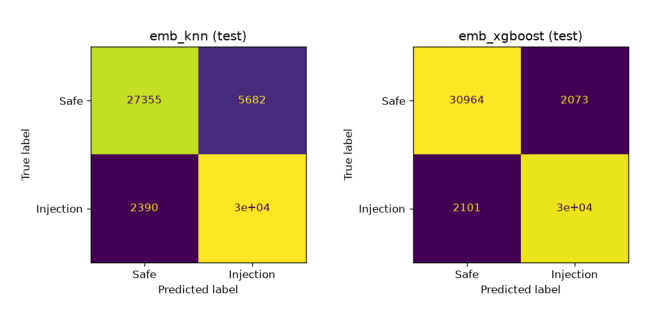

In [13]:
# Confusion matrices on the main test set
show_confusion(list(EMB), 'test')

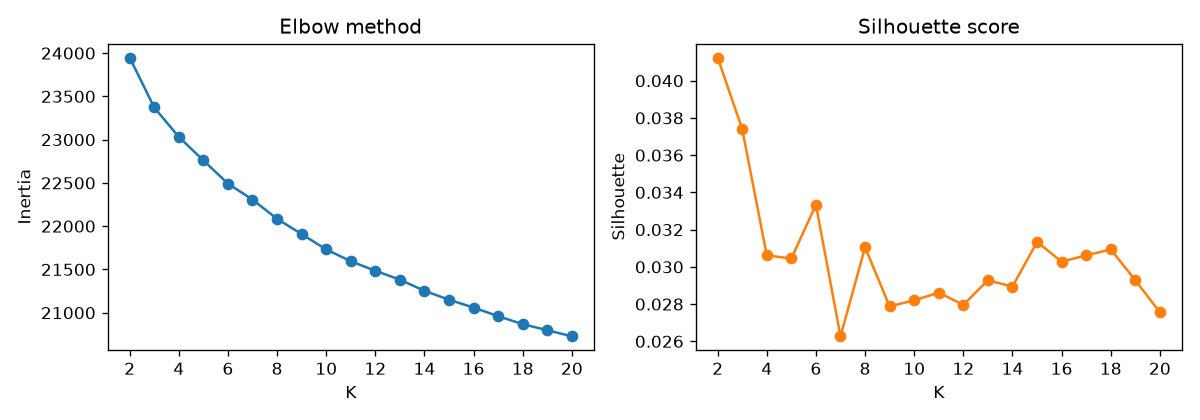

In [14]:
# K-means on embeddings: elbow and silhouette curves
Image(FIGURES_DIR / 'kmeans_emb_k_sweep.png')

In [15]:
# Purity and adjusted Rand index of embedding K-means
ekm = results['emb_kmeans']
pd.DataFrame({split: ekm[split] for split in ('train', 'test')}).T.assign(K=ekm['k'])

,purity,adjusted_rand_index,K
train,0.5143,0.0008,2
test,0.5135,0.0007,2


XGBoost on embeddings reaches F1 of 0.935 and AUROC of 0.984, and KNN reaches F1 of 0.881. Both are below the linear TF-IDF models. MiniLM is a general-purpose sentence encoder trained for semantic similarity. It compresses a prompt into 384 dimensions that describe what the text is about, and the exact word combinations that separate the two classes in this synthetic dataset (for example *reveal* next to *secrets*) are partly averaged away.

The two KNN models fail in opposite directions. On TF-IDF, KNN misses many attacks (recall 0.815, about 1,700 false alarms). On embeddings it catches more attacks (recall 0.926) but raises about 5,700 false alarms (precision 0.840). In embedding space, a harmless story about hidden secrets sits close to real extraction attacks because the meaning is similar, so the neighbourhood vote tips towards Injection.

Embedding K-means picks K = 2, where the silhouette is highest (0.041) before declining. Purity of 0.51 and adjusted Rand index of 0.0007 show that the two clusters are unrelated to the label. Since K equals the number of classes, ARI has no ceiling below 1 here, so this is genuinely chance level: the embeddings split the data along some other dimension, and safe and injection prompts on the same topic end up in the same cluster.

### 4. Final comparison on the main test set

All seven supervised models together, followed by the two clustering approaches side by side.

In [16]:
# All supervised models on the main test set
main_test = metrics_table(results, 'test', MODEL_LABELS)
main_test.join(error_counts(main_test, 'test')[['missed attacks (FN)', 'false alarms (FP)']])

,accuracy,precision,recall,f1,auroc,missed attacks (FN),false alarms (FP)
TF-IDF + Logistic Regression,0.9856,0.9887,0.9821,0.9854,0.9984,577,363
TF-IDF + SVM,0.9864,0.9905,0.9819,0.9862,0.9982,583,302
TF-IDF + XGBoost,0.9794,0.9855,0.9725,0.9790,0.9978,886,461
TF-IDF + Random Forest,0.9709,0.9732,0.9676,0.9704,0.9955,1044,857
Embeddings + XGBoost,0.9360,0.9356,0.9348,0.9352,0.9841,2101,2073
Embeddings + KNN,0.8763,0.8400,0.9258,0.8808,0.9519,2390,5682
TF-IDF + KNN,0.8823,0.9382,0.8153,0.8724,0.9573,5950,1730


In [17]:
# TF-IDF K-means vs embedding K-means
def silhouette_at_k(run):
    return next(row['silhouette'] for row in run['k_sweep'] if row['k'] == run['k'])

pd.DataFrame({
    label: {'K': run['k'], 'silhouette': silhouette_at_k(run),
            'purity (test)': run['test']['purity'],
            'adjusted Rand index (test)': run['test']['adjusted_rand_index']}
    for label, run in [('TF-IDF + LSA + K-means', results['tfidf_kmeans']),
                       ('Embeddings + K-means', results['emb_kmeans'])]
}).T

,K,silhouette,purity (test),adjusted Rand index (test)
TF-IDF + LSA + K-means,19.0000,0.0552,0.7512,0.0643
Embeddings + K-means,2.0000,0.0412,0.5135,0.0007


TF-IDF K-means is better than embedding K-means on every measure: higher silhouette (0.055 vs 0.041), higher purity (0.75 vs 0.51) and an adjusted Rand index about 100 times larger (0.064 vs 0.0007). Relative to what each K allows (about 0.10 for 19 clusters, 1 for 2 clusters), TF-IDF reaches roughly 60% of its ceiling and embeddings essentially none of theirs. Both are still weak as detectors. TF-IDF dimensions follow vocabulary, and the vocabulary of a few attack templates is distinctive enough to form some nearly pure clusters. Embeddings follow topic, and the two classes in this dataset cover the same topics. Neither clustering recovers the Safe/Injection split, which confirms that this problem needs supervision.

Among the supervised models, TF-IDF with a linear model is the best choice on the main data. The linear SVM has the highest F1 (0.986) and precision (0.991), and logistic regression has the highest recall (0.982). The recall difference between them is 6 prompts out of 32,214, which is negligible. Both train in about a minute, give calibrated probabilities and can be explained through their coefficients. Taking F1 and the external results below into account, we select TF-IDF + linear SVM as the overall best model, with logistic regression as an equivalent and simpler alternative.

### 5. External dataset (deepset) and comparison with the main data

The same supervised models evaluated on 662 prompts from a different source, then compared with their main test results.

In [18]:
# All supervised models on the external set
external = metrics_table(results, 'external', MODEL_LABELS)
external.join(error_counts(external, 'external')[['missed attacks (FN)', 'false alarms (FP)']])

,accuracy,precision,recall,f1,auroc,missed attacks (FN),false alarms (FP)
Embeddings + KNN,0.6133,0.5176,0.3916,0.4459,0.6238,160,96
TF-IDF + SVM,0.6949,0.7607,0.3384,0.4684,0.7656,174,28
TF-IDF + Logistic Regression,0.6934,0.7586,0.3346,0.4644,0.7345,175,28
TF-IDF + KNN,0.5604,0.4136,0.2548,0.3153,0.5823,196,95
Embeddings + XGBoost,0.6692,0.7683,0.2395,0.3652,0.6694,200,19
TF-IDF + Random Forest,0.6435,0.6452,0.2281,0.3371,0.6632,203,33
TF-IDF + XGBoost,0.6722,0.9792,0.1787,0.3023,0.6691,216,1


In [19]:
# Main test vs external, per model
comparison = pd.DataFrame({
    'F1 main': main_test['f1'], 'F1 external': external['f1'],
    'recall main': main_test['recall'], 'recall external': external['recall'],
    'AUROC main': main_test['auroc'], 'AUROC external': external['auroc'],
})
comparison['F1 drop'] = comparison['F1 main'] - comparison['F1 external']
comparison.sort_values('F1 external', ascending=False)

,F1 main,F1 external,recall main,recall external,AUROC main,AUROC external,F1 drop
TF-IDF + SVM,0.9862,0.4684,0.9819,0.3384,0.9982,0.7656,0.5178
TF-IDF + Logistic Regression,0.9854,0.4644,0.9821,0.3346,0.9984,0.7345,0.5210
Embeddings + KNN,0.8808,0.4459,0.9258,0.3916,0.9519,0.6238,0.4349
Embeddings + XGBoost,0.9352,0.3652,0.9348,0.2395,0.9841,0.6694,0.5700
TF-IDF + Random Forest,0.9704,0.3371,0.9676,0.2281,0.9955,0.6632,0.6333
TF-IDF + KNN,0.8724,0.3153,0.8153,0.2548,0.9573,0.5823,0.5571
TF-IDF + XGBoost,0.9790,0.3023,0.9725,0.1787,0.9978,0.6691,0.6767


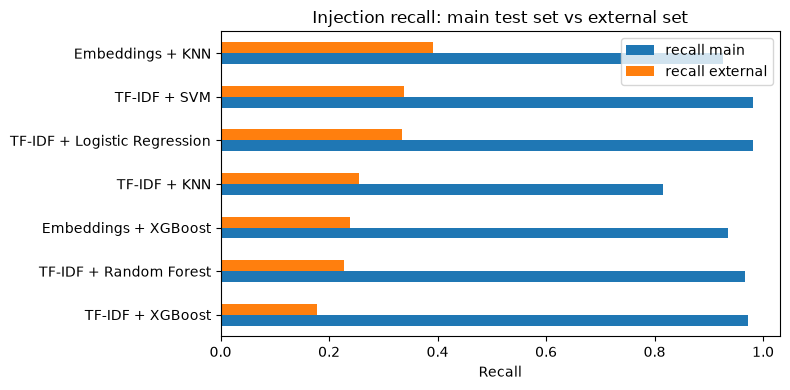

In [20]:
# Injection recall on both test sets
comparison[['recall main', 'recall external']].sort_values('recall external').plot.barh(
    figsize=(8, 4), title='Injection recall: main test set vs external set')
plt.xlabel('Recall')
plt.tight_layout()

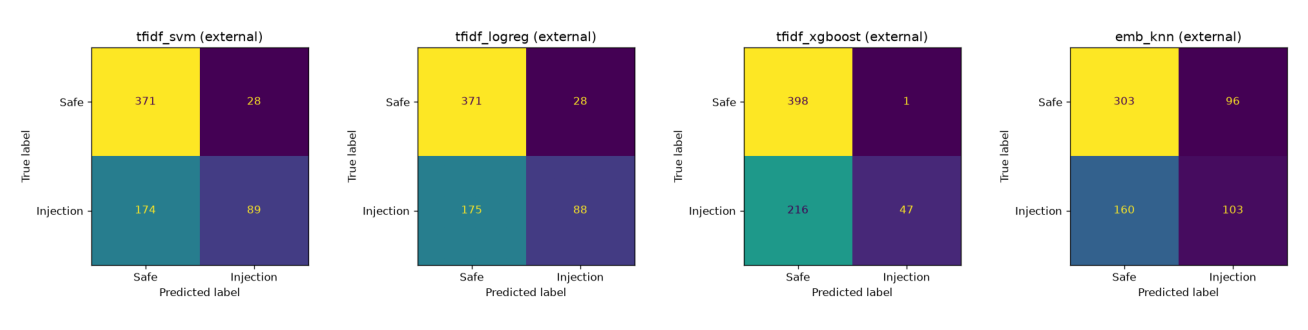

In [21]:
# Confusion matrices on the external set
show_confusion(['tfidf_svm', 'tfidf_logreg', 'tfidf_xgboost', 'emb_knn'], 'external')

In [22]:
# Embedding K-means on the external set (TF-IDF K-means was not evaluated there)
pd.Series(results['emb_kmeans']['external'], name='Embeddings + K-means (external)')

purity                0.6027
adjusted_rand_index   0.0109
Name: Embeddings + K-means (external), dtype: float64

Every model degrades sharply on the external set. F1 falls from 0.87 to 0.99 on the main test set to between 0.30 and 0.47, and recall falls to between 0.18 and 0.39. The errors are one-sided: precision stays moderate to high for most models while recall collapses, so the models fail by missing attacks rather than by raising false alarms. The SVM, for example, misses 174 of the 263 external attacks.

AUROC drops less, to between 0.58 and 0.77. Part of the ranking still transfers, so external attacks tend to receive higher scores than external safe prompts, but most of those scores fall below the 0.5 threshold. The decision boundary learned on the main data is miscalibrated for the new distribution, and a lower threshold would recover some recall at the cost of precision.

The cause is a distribution shift on two levels, both visible in the EDA. The inputs change: external prompts are much shorter (median 11 words against 50), partly German, and written by real users. The attacks themselves also change: the main data hides requests for secrets inside stories and code, while the external attacks are direct overrides ("forget everything above") and role-play jailbreaks. For TF-IDF, German words and new phrasings are mostly absent from the vocabulary, so the vectors carry little evidence and the models default to Safe. TF-IDF XGBoost shows this most clearly, with precision of 0.979 but recall of only 0.179: it flags an attack only when the specific n-grams its trees split on are present.

Embeddings + KNN has the highest external recall (0.39) and the smallest relative drop, which suggests that semantic similarity transfers somewhat better than exact vocabulary, but its precision is only 0.52. Embedding K-means on the external set reaches purity of 0.603, which is exactly the share of the majority class (Safe), so the clusters carry no information there.

The linear SVM remains the best overall model, with the highest external F1 (0.468) and AUROC (0.766). However, no model is reliable on attack styles it has not seen. The bottleneck is the diversity of the training data, not the choice of classifier, and the in-domain scores near 0.99 should not be read as real-world performance.

### AI Tool Use

- AI was used to add comments to the code and documentation to the functions in the Python files.
- The model used for this was Claude Opus 5.5.
- It was used to plot the five confusion matrices with colors.
- It was also used to fix the grammar in the interpretations.